# Notebook 04 — Propensity Score Matching (PSM)

**What PSM does:** Matches each treated customer to a similar untreated customer based on their *probability of being treated* (propensity score), estimated from observed covariates. The treatment effect is then estimated on matched pairs, controlling for observed confounding.

**Steps:**
1. Estimate propensity scores with logistic regression
2. Check overlap (common support)
3. Match treated to nearest-neighbour control
4. Assess post-match covariate balance
5. Estimate ATT on matched sample
6. Compare to naive and DiD estimates


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
from scipy import stats

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 120})

FEATURE_COLS = ['recency', 'log_history', 'mens', 'womens', 'newbie',
                'channel_web', 'channel_multi', 'zip_urban', 'zip_suburban']

df = pd.read_csv('../data/hillstrom_clean.csv')

## 1. Estimate propensity scores

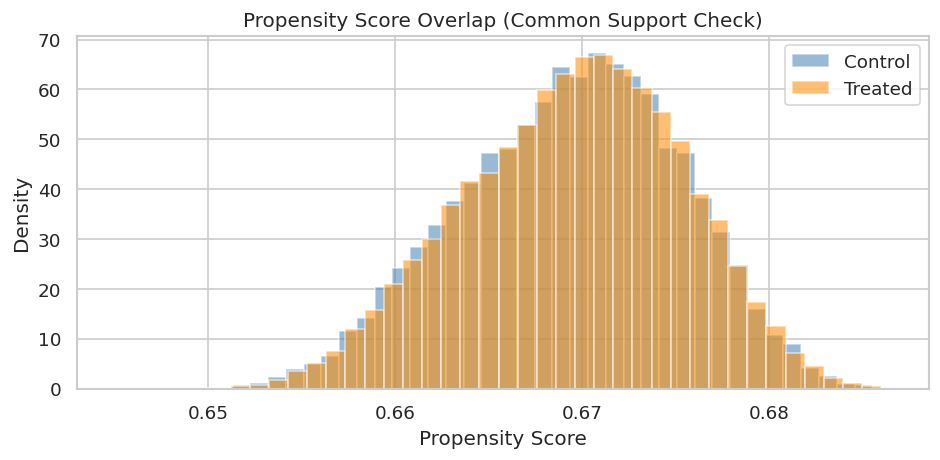

Propensity score range — Treated:  [0.645, 0.686]
Propensity score range — Control:  [0.648, 0.686]


In [2]:
X = df[FEATURE_COLS].values
T = df['treated'].values

lr = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr.fit(X, T)
df['propensity'] = lr.predict_proba(X)[:, 1]

# Overlap plot
fig, ax = plt.subplots(figsize=(8, 4))
for t, label, color in [(0,'Control','steelblue'),(1,'Treated','darkorange')]:
    ax.hist(df.loc[df.treated==t, 'propensity'], bins=40, alpha=0.55,
            label=label, color=color, density=True)
ax.set_xlabel('Propensity Score')
ax.set_ylabel('Density')
ax.set_title('Propensity Score Overlap (Common Support Check)')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/04_propensity_overlap.png', bbox_inches='tight')
plt.show()

print(f'Propensity score range — Treated:  [{df.loc[df.treated==1,"propensity"].min():.3f}, {df.loc[df.treated==1,"propensity"].max():.3f}]')
print(f'Propensity score range — Control:  [{df.loc[df.treated==0,"propensity"].min():.3f}, {df.loc[df.treated==0,"propensity"].max():.3f}]')

## 2. Nearest-neighbour matching (1:1, without replacement)

In [3]:
treated_idx = df.index[df['treated'] == 1].tolist()
control_idx = df.index[df['treated'] == 0].tolist()

ps_treated = df.loc[treated_idx, 'propensity'].values.reshape(-1, 1)
ps_control = df.loc[control_idx, 'propensity'].values.reshape(-1, 1)

nn = NearestNeighbors(n_neighbors=1, algorithm='ball_tree')
nn.fit(ps_control)
distances, indices = nn.kneighbors(ps_treated)

matched_control_idx = [control_idx[i[0]] for i in indices]

# Caliper: discard matches where |PS_treated - PS_control| > 0.05
caliper = 0.05
good_match = distances.flatten() <= caliper
matched_treated = [treated_idx[i] for i, ok in enumerate(good_match) if ok]
matched_control = [matched_control_idx[i] for i, ok in enumerate(good_match) if ok]

print(f'Treated units:             {len(treated_idx):,}')
print(f'Matches within caliper:    {sum(good_match):,}  ({100*sum(good_match)/len(treated_idx):.1f}%)')

df_matched = pd.concat([
    df.loc[matched_treated],
    df.loc[matched_control]
])

Treated units:             42,848
Matches within caliper:    42,848  (100.0%)


## 3. Post-match covariate balance

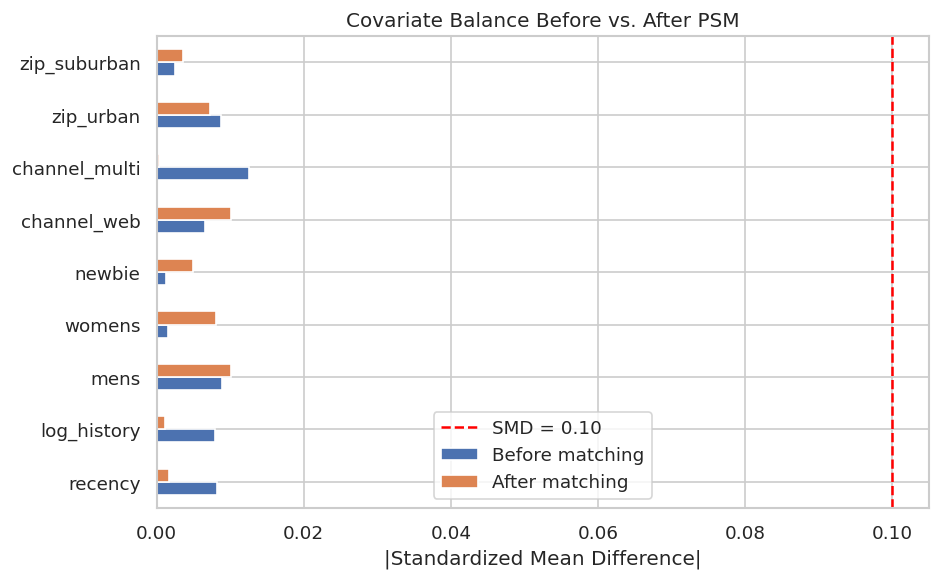

In [4]:
def smd(a, b):
    pooled = np.sqrt((a.std()**2 + b.std()**2) / 2)
    return (a.mean() - b.mean()) / pooled if pooled > 0 else 0

t_m = df_matched[df_matched.treated==1]
c_m = df_matched[df_matched.treated==0]
t_u = df[df.treated==1]
c_u = df[df.treated==0]

balance = pd.DataFrame({
    'Before matching': [abs(smd(t_u[f], c_u[f])) for f in FEATURE_COLS],
    'After matching':  [abs(smd(t_m[f], c_m[f])) for f in FEATURE_COLS],
}, index=FEATURE_COLS)

fig, ax = plt.subplots(figsize=(8, 5))
balance.plot(kind='barh', ax=ax)
ax.axvline(0.10, color='red', linestyle='--', label='SMD = 0.10')
ax.set_title('Covariate Balance Before vs. After PSM')
ax.set_xlabel('|Standardized Mean Difference|')
ax.legend()
plt.tight_layout()
plt.savefig('../outputs/04_psm_balance.png', bbox_inches='tight')
plt.show()

## 4. ATT on matched sample

In [5]:
print('=== PSM Estimated ATT ===')
for outcome in ['visit', 'conversion', 'spend']:
    t_out = t_m[outcome].values
    c_out = c_m[outcome].values
    att   = t_out.mean() - c_out.mean()
    tstat, pval = stats.ttest_rel(t_out, c_out)
    se    = (t_out - c_out).std() / np.sqrt(len(t_out))
    ci_lo = att - 1.96 * se
    ci_hi = att + 1.96 * se
    print(f'{outcome:12s}  ATT={att:.4f}  95%CI=[{ci_lo:.4f}, {ci_hi:.4f}]  p={pval:.4f}')

=== PSM Estimated ATT ===
visit         ATT=0.0604  95%CI=[0.0562, 0.0645]  p=0.0000
conversion    ATT=0.0144  95%CI=[0.0114, 0.0174]  p=0.0000
spend         ATT=1.0707  95%CI=[0.8904, 1.2511]  p=0.0000


## 5. Compare naive vs. PSM estimates

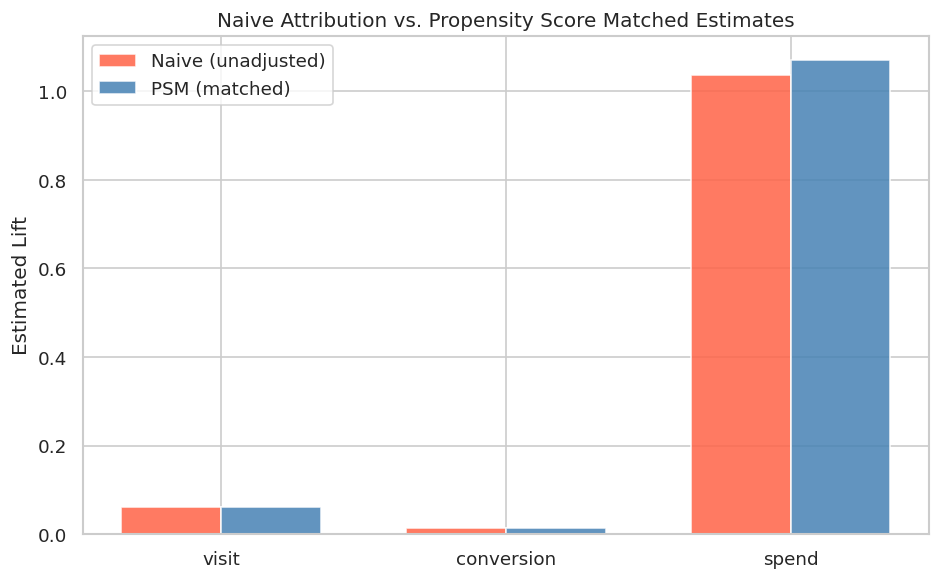

In [6]:
outcomes  = ['visit', 'conversion', 'spend']
naive_est = [(df[df.treated==1][o].mean() - df[df.treated==0][o].mean()) for o in outcomes]
psm_est   = [(t_m[o].mean() - c_m[o].mean()) for o in outcomes]

x = np.arange(len(outcomes))
w = 0.35
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - w/2, naive_est, w, label='Naive (unadjusted)', color='tomato', alpha=0.85)
ax.bar(x + w/2, psm_est,   w, label='PSM (matched)',      color='steelblue', alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(outcomes)
ax.set_ylabel('Estimated Lift')
ax.set_title('Naive Attribution vs. Propensity Score Matched Estimates')
ax.legend()
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('../outputs/04_naive_vs_psm.png', bbox_inches='tight')
plt.show()